# <div align="center">Klasteryzacja</div>
---

**Z twojego zbioru danych zniknęły prawie wszystkie labelki!**

Każdy punkt w Twoim zbiorze treningowym ma po dwie zmienne oraz jedną z trzech klas. Miał on posłużyć aby wytrenować na nim modele uczenia maszynowego, które byłyby w stanie klasyfikować nowe punkty testowe. Niestety, plik z przyporządkowanymi klasami dla każdego punktu treningowego uległ uszkodzeniu i tylko dla kilku punktów wiemy, do jakich klas należą. Czy mimo to jesteś w stanie odzyskać prawdziwe klasy?

W tym zadaniu będziemy korzystać z biblioteki `numpy` a nie `torch`, ponieważ nie będziemy potrzebować karty graficznej ani obliczeń gradientowych.

In [10]:
import numpy as np

Pobierzmy najpierw wszystkie dane dostępne w zadaniu:

In [11]:
FINAL_EVALUATION_MODE = False  # Ta flaga zostanie automatycznie zmieniona na True na systemie sprawdzającym.

from zipfile import ZipFile
import os

if not (os.path.exists('data.npy') and os.path.exists('corrupted_labels.npy')):
    !curl -o train.zip https://sprawdzai.org/static/files/dataset/64127ddb-acd1-4118-9383-3236262269f6
    with ZipFile('train.zip', 'r') as z:
        z.extractall()

Załadujmy uszkodzone dane treningowe:

In [12]:
X = np.load('data.npy')
y = np.load('corrupted_labels.npy')

print(X.shape)
print(y.shape)

(171, 2)
(171,)


`X` ma kształt `(171, 2)` co oznacza, że mamy `171` punktów danych, z których każda ma dwie zmienne. Z kolei `y` ma kształt `(171,)` - są to klasy dla każdego punktu treningowego.

In [13]:
y

array([-1, -1, -1, -1, -1, -1, -1, -1, -1,  0, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  0, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1,  1,  0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1,  2, -1, -1, -1,  2, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1])

Większość z tych klas to `-1` - są to klasy uszkodzone. Tylko kilka z nich ma wartości inne niż `-1` i są to zawsze `0`, `1` lub `2` reprezentujące prawdziwe klasy tamtych punktów. Celem zadania jest zrekonstruowanie tych klas, czyli stworzenie nowego numpy array `y_new` o kształcie `(171,)`, który będzie zawierał wyłącznie wartości `0`, `1` lub `2` będącymi przewidzianymi przez Twój algorytm klasami zamiast wartości `-1`. Ponieważ każdy punkt treningowy składa się z dwóch zmiennych, możemy je zwizualizować na dwuwymiarowym układzie współrzędnych. Zrobimy to za pomocą biblioteki `matplotlib` - nie musisz zbytnio wchodzić w ten kod.

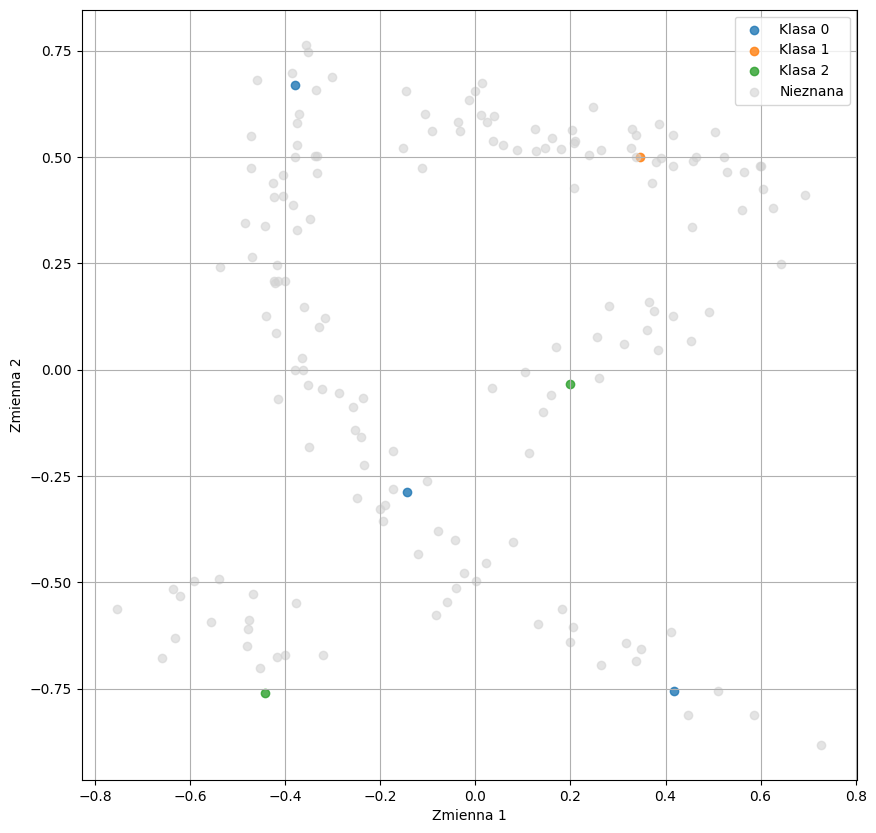

In [14]:
import matplotlib.pyplot as plt

plt.figure(None, (10, 10))
for i in range(3):
    plt.scatter(X[y == i, 0], X[y == i, 1], label=f"Klasa {i}", alpha=0.8)
plt.scatter(X[y == -1, 0], X[y == -1, 1], color='lightgray', label="Nieznana", alpha=0.6)

plt.xlabel("Zmienna 1")
plt.ylabel("Zmienna 2")
plt.legend()
plt.grid(True)
plt.show()

Zwróć uwagę na skalę osi X oraz osi Y. Co zauważasz? Czy potrzebujemy tutaj normalizacji danych?

<details>
    <summary>Odpowiedź:</summary>
    Nie, bo obie osie są niemalże idealnie wycentrowane wokół zera, mają praktycznie tę samą skalę w sensownym zakresie -1 do 1. Normalizacja mogłaby tu lekko pomóc jeśli będziemy korzystać z algorytmów uczenia maszynowego, ale zysk byłby raczej marginalny.
</details>

Być może dostrzegasz już, jak można użyć klasteryzacji aby rozwiązać ten problem... W swoim rozwiązaniu musisz edytować poniższą komórkę, która zrekonstruuje poprawne klasy dla każdego punktu. Innymi słowy dla każdego punktu który teraz ma nieznaną (uszkodzoną) klasę `-1`, chcesz mu przypisać inną klasę `0`, `1` lub `2`:

In [15]:
from sklearn.cluster import DBSCAN

# Używamy algorytmu DBSCAN do podziału na klastry oparte na gęstości
dbscan = DBSCAN(eps=0.15, min_samples=1)
cluster_numbers = dbscan.fit_predict(X)
total_clusters = int(cluster_numbers.max()) + 1

y_new = np.zeros(len(y))

# Mapujemy każdy klaster na odpowiadającą mu klasę na podstawie znanych etykiet
for current_cluster in range(total_clusters):
    cluster_class = 0
    for j in range(len(y)):
        if cluster_numbers[j] == current_cluster:
            if y[j] != -1:
                cluster_class = y[j]
                break

    # Przypisujemy odnalezioną klasę wszystkim punktom w danym klastrze
    for j in range(len(y)):
        if cluster_numbers[j] == current_cluster:
            y_new[j] = cluster_class

Możemy zwizualizować wyniki twojej funkcji (przykładowe rozwiązanie ustawia wszystkie klasy na `0`, co nie daje zbyt dobrych wyników, nawet wizualnie...):

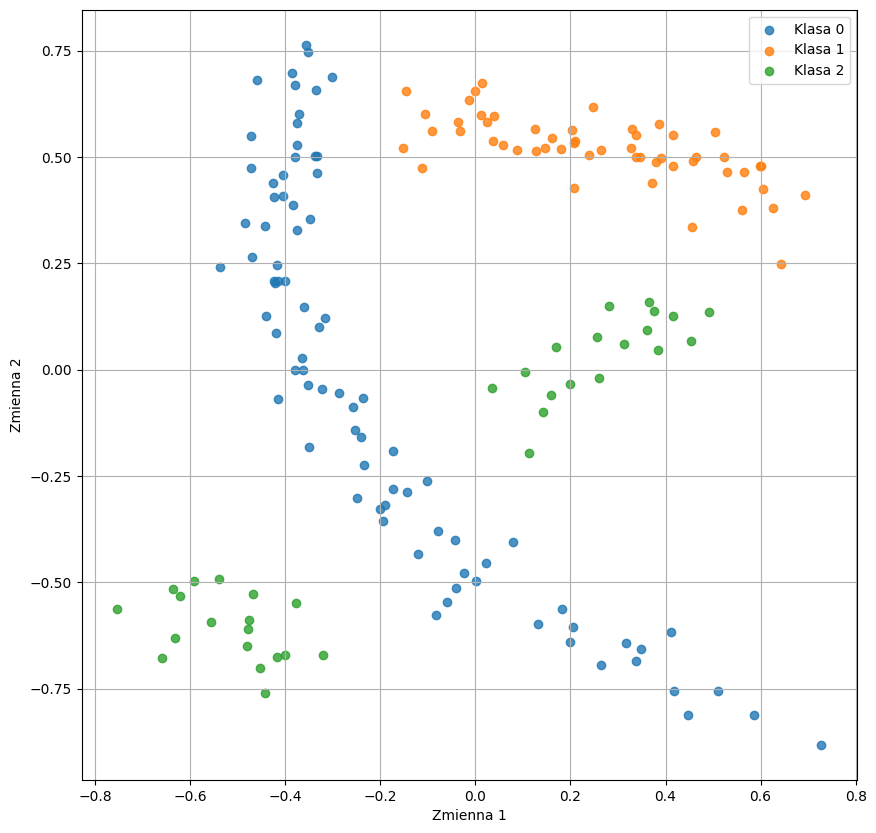

In [16]:
if (y_new == -1).any():
    raise Exception("Jedną z klas które zwróciła funkcja 'solution' była nieznana klasa -1. Twoja funkcja powinna zwracać wyłącznie klasy 0, 1 lub 2!")

plt.figure(None, (10, 10))
for i in range(3):
    plt.scatter(X[y_new == i, 0], X[y_new == i, 1], label=f"Klasa {i}", alpha=0.8)

plt.xlabel("Zmienna 1")
plt.ylabel("Zmienna 2")
plt.legend()
plt.grid(True)
plt.show()

Na koniec zapiszemy `y_new`, aby SprawdzAI mógł to odczytać i ocenić:

In [17]:
np.save('labels.npy', y_new)

SprawdzAI uruchomi wszystkie komórki tego notatnika, który powinien stworzyć plik `labels.npy` - tylko ten plik będzie później oceniany. Metryką ewaluacji Twojego rozwiązania będzie procent punktów, dla których poprawnie uda Ci się zrekonstruować klasy. Jeśli wyniesie on $60\%$ to otrzymasz $0$ punktów, a jeśli wyniesie $100\%$ to otrzymasz $100$ punktów. Pomiędzy tymi wartościami liczba punktów rośnie liniowo.

<details>
    <summary>Podpowiedź 1:</summary>
    Zauważ, że dane składają się z czterech klastrów. Być może wystarczy przeprowadzić klasteryzację i jakoś sprytnie wykorzystać wyniki?
</details>

<details>
    <summary>Podpowiedź 2:</summary>
    Przeprowadź klasteryzację tych punktów za pomocą algorytmu DBSCAN. Być może będziesz musiał(-a) nieco dopasować parametry eps i min_samples aby dobrze zadziałało. Następnie dla każdego klastra sprawdź, do jakiej klasy powinny się zaliczać wszystkie jego punkty, i tą klasę zaznacz wszystkim punktom które mają zepsutą klasę -1.

```python
dbscan = DBSCAN(eps=???, min_samples=???)
cluster_numbers = dbscan.fit_predict(X)  # <---- Numpy array o kształcie (171,), przechowuje numer klastra do którego należy każdy z punktów
total_clusters = int(cluster_numbers.max())   # <---- Liczba wszystkich znalezionych klastrów
```
</details>

<details>
    <summary>Podpowiedź 3:</summary>
    Wystarczy, że przeiterujesz się po każdym klastrze (jest ich w sumie int(cluster_numbers.max())). Dla każdego z nich przeiteruj się po wszystkich punktach, i gdy tylko znajdziesz jakiś punkt który ma ustawioną klasę (tzn. inną niż -1), tą klasę nadaj całemu klastrowi - tzn. taką klasę ustaw wszystkim punktom wewnątrz tego klastra.
</details>

<details>
    <summary>Podpowiedź 4:</summary>
    Dobrze działającymi w tym przypadku parametrami dla DBSCAN będą DBSCAN(eps=0.15, min_samples=1)
</details>

<details>
    <summary>Rozwiązanie:</summary>

```python
dbscan = DBSCAN(eps=0.15, min_samples=1)
cluster_numbers = dbscan.fit_predict(X)  # <---- Numpy array o kształcie (171,), przechowuje numer klastra do którego należy każdy z punktów
total_clusters = int(cluster_numbers.max())   # <---- Liczba wszystkich znalezionych klastrów
# Zróbmy zmienną z naszą odpowiedzią, na razie wpiszmy, że każdy punkt jest z klasy 0 - później to zmienimy
y_new = np.zeros(len(y))
# Przeiterujmy się po każdym klastrze:
for current_cluster in range(total_clusters):
    # W każdym klastrze powinien być co najmniej jeden punkt, który ma ustawioną poprawną klasę (tzn. inną niż -1).
    # Wtedy możemy tą klasę przyporządkować każdemu innemu punktowi w naszym klastrze.
    # Najpierw znajdźmy tą klasę:
    cluster_class = 0
    for j in range(len(y)):
        # Sprawdzamy czy ten punkt jest wewnątrz tego klastra:
        if cluster_numbers[j] == current_cluster:
            # Jeśli ma klasę inną niż -1, to taką klasę nadamy całemu klastrowi:
            if y[j] != -1:
                cluster_class = y[j]
    
    # Teraz nadamy tą klasę wszystkim punktom w klastrze:
    for j in range(len(y)):
        # Sprawdzamy czy ten punkt jest wewnątrz tego klastra:
        if cluster_numbers[j] == current_cluster:
            # I nadajemy mu klasę tego klastra
            y_new[j] = cluster_class

```
</details>

<details>
    <summary>Podpowiedź do rozwiązania alternatywnego:</summary>
    Jest również możliwe nieco prostsze rozwiązanie alternatywne, ale da mniej punktów. Spróbuj wykorzystać model KNN.
</details>

<details>
    <summary>Rozwiązanie alternatywne:</summary>

```python
# Wytrenujemy po prostu model KNN tylko na tych punktach, które mają przyporządkowaną klasę
from sklearn.neighbors import KNeighborsClassifier

# Mamy bardzo mało danych z przyporządkowanymi klasami, więc weźmiemy tylko jednego sąsiada.
# Gdybyśmy wzięli więcej, to np. klasa 1 mogłaby nigdy nie zostać wybrana, bo należy do niej tylko jeden punkt,
# czyli już dla trzech sąsiadów zawsze znalazłyby się dwa punkty które mają inne klasy.
model = KNeighborsClassifier(n_neighbors=1)

# Wytrenujemy model tylko na danych z klasą inną niż -1
model.fit(X[y != -1], y[y != -1])

# Weźmiemy klasy zgodnie z tym, co przewiduje nasz model KNN
y_new = model.predict(X)
```
</details>